# 15 · 질량을 범위(η)로 넣을까, 세기(w)로 넣을까

> 질량이 큰 분절일수록 더 멀리 피하게 하고 싶다. 비용에서 질량을 넣을 수 있는 자리는 둘이다. 비용이 켜지는 거리 η와 비용의 세기 w. 두 자리는 이격을 전혀 다르게 바꾼다.

| | |
|---|---|
| **이 노트의 질문** | 질량이 클수록 더 멀리 피하게 하고 싶을 때, 질량으로 η를 키우는 것과 w를 키우는 것은 이격을 어떻게 다르게 바꾸는가 |
| **최종 목표** | 균형 이격 $d_{eq} = \eta\,(1 - g/w)$로 두 방식의 차이를 설명할 수 있다 |
| **연구의 어느 결정과 연결되는가** | 질량을 비용의 어디에 넣을지(η 스케일링 vs 가중치). 16의 방향별 η(u), 19의 필요 이격 거리로 이어진다 |
| **이 노트에서 바꾸는 요인** | 질량을 넣는 자리(η 또는 w)와 질량 값. 사람은 서 있고(기준 자세), 질량은 방향과 무관한 스칼라 하나로 사람 전체에 쓴다 |

**지금 위치:** 01~13 기초·MPPI·프로젝트 → 14 움직이는 사람 → **15 η와 w** → 16 방향별 질량 → 17 ESS → 18 비용 불연속과 떨림 → 19 필요 이격 거리 → 20 안전 필터 → 21 지연 → 22 cuRobo 확인

**필요한 것:** [06](06_mppi_obstacles.ipynb) η 장애물 비용, [08](08_robot_arm.ipynb) η 비용 식, [11](11_hand_cost_mass.ipynb) 질량 → η, [14](14_moving_obstacle.ipynb) 공통 장면 · **예상 시간:** 50분

## 복습 퀴즈

<details><summary>1. 08의 η 비용에서 간격 d가 0 ≤ d < η이면 칸 하나의 비용은? d < 0(겹침)이면?</summary>

0 ≤ d < η: $w\,(\eta - d)^2 / (2\eta)$. d < 0: $w\,\big((\eta - d) - \eta/2\big)$ (1차로 커진다). d ≥ η이면 0.
</details>

<details><summary>2. 사람 분절의 유효질량 m_h = 40 kg, 로봇 m_r = 5 kg이면 환산질량 μ = m_h m_r/(m_h + m_r)는?</summary>

200 / 45 = **4.44 kg**. 사람이 아무리 무거워도 μ는 m_r = 5 kg을 넘지 못한다.
</details>

<details><summary>3. 11(선행 프로젝트)에서 질량은 비용의 어디에 들어갔나? (a) η (b) w (c) 둘 다</summary>

**(a)** 질량이 클수록 η를 키웠다(질량 → η). 이 노트는 그 선택을 w에 넣는 것과 비교한다.
</details>

In [1]:
import sys, time
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))          # 노트 폴더 (common14 패키지)
import numpy as np
from functools import partial
from common14 import *
from common14 import scene as S
plt = setup_plot()

ex, ey = np.array([1.0, 0.0]), np.array([0.0, 1.0])
REAL = {                                      # 회차 0에서 고정한 실제 환산질량 4개 [kg]
    '팔 길이 방향': float(reduced_mass(directional_mass(ex, 'arm'))),
    '팔 수직 (자유)': float(reduced_mass(directional_mass(-ey, 'arm'))),
    '팔 수직 (ROM 잠금)': float(reduced_mass(directional_mass(ey, 'arm'))),
    '몸통': float(reduced_mass(directional_mass(ex, 'torso'))),
}
real = sorted(REAL.values())
MUS = sorted(real + [0.5 * (a + b) for a, b in zip(real[:-1], real[1:])])   # 실제 4개 + 그 사이 3개
MU_REF = REAL['몸통']
for name, mu in REAL.items():
    print('%-14s μ = %.3f kg' % (name, mu))
print('스윕할 μ [kg]:', ' '.join('%.3f' % m for m in MUS))

팔 길이 방향        μ = 0.833 kg
팔 수직 (자유)      μ = 1.875 kg
팔 수직 (ROM 잠금)  μ = 3.529 kg
몸통             μ = 4.444 kg
스윕할 μ [kg]: 0.833 1.354 1.875 2.702 3.529 3.987 4.444


## 1. 문제 — 질량을 비용의 어디에 넣을까

### 문제
14까지 사람 비용은 모든 분절에 같은 η = 0.10 m, w = 100을 썼다. 이제 질량이 큰 쪽(몸통, ROM에 잠긴 팔)에서는 더 멀리 피하게 하고 싶다. 08의 η 비용에서 질량을 넣을 수 있는 자리는 둘이다.

| 방식 | 식 | 바뀌는 것 |
|---|---|---|
| **(a) η 스케일링** | $\eta(\mu) = \eta_0\,(\mu/\mu_{ref})^p$, w = 100 고정 | 비용이 **켜지는 거리** |
| **(b) w 스케일링** | $w(\mu) = w_0\,(\mu/\mu_{ref})^p$, η = 0.10 m 고정 | 비용의 **세기**(높이) |

- $\mu_{ref}$는 몸통의 환산질량(4.444 kg)이다. 그래서 몸통에서는 두 방식 모두 η = 0.10 m, w = 100으로 14와 같다. 몸통보다 가벼운 분절은 η 또는 w가 줄어든다.
- p는 두 가지를 본다. p = 1(질량에 비례)과 p = 1/2. p = 1/2은 충돌할 때 최대 충돌력이 $\sqrt{\mu}$에 비례한다(같은 속도, 같은 접촉 강성이면 $F = v\sqrt{k\mu}$)는 데서 나온 값이다.

In [2]:
ETA0, W0 = S.ETA0, S.W_HUMAN

def eta_of(mu, p):
    return ETA0 * (mu / MU_REF) ** p

def w_of(mu, p):
    return W0 * (mu / MU_REF) ** p

def params(meth, p, mu):
    # 방식 meth('eta' 또는 'w'), 지수 p, 질량 mu → (η, w)
    return (eta_of(mu, p), W0) if meth == 'eta' else (ETA0, w_of(mu, p))

print('%-8s | %-26s | %-26s' % ('μ [kg]', '(a) η [m]  p=1 / p=1/2', '(b) w  p=1 / p=1/2'))
for mu in MUS:
    print('%-8.3f | %8.4f / %-15.4f | %8.1f / %-15.1f' % (mu, eta_of(mu, 1), eta_of(mu, 0.5), w_of(mu, 1), w_of(mu, 0.5)))

μ [kg]   | (a) η [m]  p=1 / p=1/2     | (b) w  p=1 / p=1/2        
0.833    |   0.0188 / 0.0433          |     18.8 / 43.3           
1.354    |   0.0305 / 0.0552          |     30.5 / 55.2           
1.875    |   0.0422 / 0.0650          |     42.2 / 65.0           
2.702    |   0.0608 / 0.0780          |     60.8 / 78.0           
3.529    |   0.0794 / 0.0891          |     79.4 / 89.1           
3.987    |   0.0897 / 0.0947          |     89.7 / 94.7           
4.444    |   0.1000 / 0.1000          |    100.0 / 100.0          


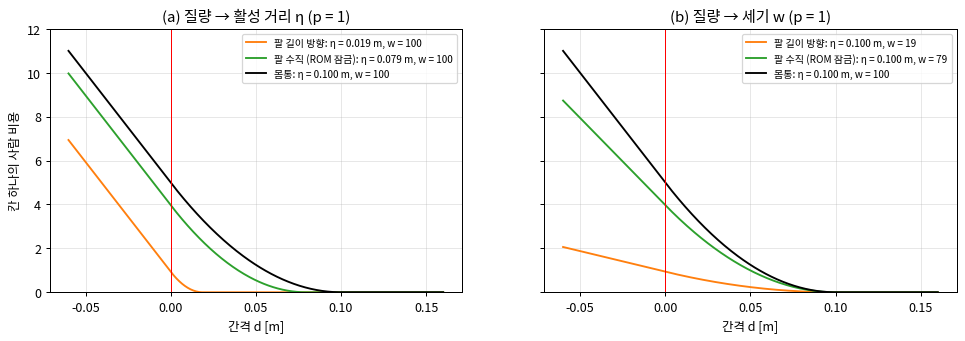

In [3]:
d = np.linspace(-0.06, 0.16, 400)
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, (meth, title) in zip(axs, [('eta', '(a) 질량 → 활성 거리 η'), ('w', '(b) 질량 → 세기 w')]):
    for name, col in [('팔 길이 방향', 'C1'), ('팔 수직 (ROM 잠금)', 'C2'), ('몸통', 'k')]:
        eta, w = params(meth, 1, REAL[name])
        ax.plot(d, eta_cost(d, eta, w), color=col, label=f'{name}: η = {eta:.3f} m, w = {w:.0f}')
    ax.axvline(0, color='r', lw=0.8)
    ax.set_xlabel('간격 d [m]'); ax.set_ylim(0, 12); ax.set_title(title + ' (p = 1)'); ax.legend(fontsize=8)
axs[0].set_ylabel('칸 하나의 사람 비용')
plt.show()

(a)는 비용이 켜지는 지점(곡선이 0에서 올라가기 시작하는 간격)이 질량에 따라 오른쪽으로 옮겨 간다. (b)는 켜지는 지점은 0.10 m로 같고 곡선의 높이만 바뀐다.

**예측해 보기:** 로봇이 사람 앞에서 멈춘다면, 가벼운 팔(μ = 0.83 kg)일 때 멈추는 이격은 (a)와 (b)에서 각각 몇 m쯤일까? 몸통일 때와 비교해 보자.

## 2. 균형 이격 d_eq — 당김과 밀어냄이 같아지는 거리

### 아이디어
로봇은 목표 쪽으로 당겨지고 사람 쪽에서 밀려난다. 두 힘이 같아지는 거리에서 멈춘다. 여기서 "힘"은 비용의 **기울기**(거리를 조금 바꿨을 때 비용이 얼마나 바뀌는가)다.

- **목표 비용의 기울기 g:** 로봇이 목표 쪽으로 1 m 더 가면 칸 하나의 목표 비용이 얼마나 줄어드는가. 목표가 로봇을 당기는 세기다. 목표 비용은 목표까지 거리 D의 제곱이므로 g는 D에 비례한다(멀수록 세게 당긴다).
- **사람 비용의 기울기:** 사람 쪽으로 1 m 더 가면 칸 하나의 사람 비용이 얼마나 늘어나는가. 08의 η 비용을 간격 d로 미분하면
  - $0 \le d < \eta$: $w\,(\eta - d)/\eta$ (d = η에서 0, 표면(d = 0)에서 w)
  - $d < 0$(겹침): $w$ (일정)

### 유도
멈춘 자리에서는 두 기울기가 같다.

$$g = w\,\frac{\eta - d_{eq}}{\eta} \quad\Longrightarrow\quad d_{eq} = \eta\left(1 - \frac{g}{w}\right)$$

- $g < w$이면 $0 < d_{eq} < \eta$: η 경계보다 조금 안쪽에서 멈춘다. w가 커질수록 $d_{eq}$는 η에 가까워지지만 **η를 넘지 못한다**.
- $g \ge w$이면 균형점이 없다. 밀어냄은 표면에서 최대 w이고 겹친 뒤에도 w에 머물러, 당김 g를 이기지 못한다. 로봇은 **경계 안으로 들어간다**.

먼저 공통 모듈의 실제 비용식이 위 기울기와 맞는지 수치 미분으로 확인한다.

In [4]:
eta, w, h = 0.10, 100.0, 1e-6
for d0, formula, name in [(0.04, w * (eta - 0.04) / eta, 'w(η−d)/η'), (-0.02, w, 'w')]:
    num = -(eta_cost(d0 + h, eta, w) - eta_cost(d0 - h, eta, w)) / (2 * h)   # 간격이 줄어드는 쪽으로 미분
    print('간격 %+.2f m: 밀어냄 기울기 수치 미분 %.3f, 식 %s = %.3f' % (d0, num, name, formula))

간격 +0.04 m: 밀어냄 기울기 수치 미분 60.000, 식 w(η−d)/η = 60.000
간격 -0.02 m: 밀어냄 기울기 수치 미분 100.000, 식 w = 100.000


### 이 장면의 g
`common14`의 목표 비용은 칸마다 $W_{goal} D^2$이고, 마지막 칸에 $W_{term} D^2$가 더 붙는다($W_{goal} = 1$, $W_{term} = 20$). 로봇이 멈춰 있는 계획(입력 0)이면 30칸 모두 같은 자리라 목표 비용 합은 $(30\,W_{goal} + W_{term})\,D^2$이다. 사람 비용도 30칸 모두 같으니 합은 30 × (칸 하나의 비용)이다.

30칸 합끼리의 기울기를 맞추면 30으로 나눈 칸 하나 기준 식과 같다. 그러므로 칸 하나 기준의 g는

$$g = 2\left(W_{goal} + \frac{W_{term}}{30}\right) D = 3.33\,D$$

**1D 확인 장면:** 로봇은 x축 위로만 움직인다(돌아갈 수 없다). 목표는 사람 몸통 뒤쪽 표면 (1.50, 0)에 둔다. 로봇은 사람을 뚫고 갈 수 없으니 팔 끝 앞에서 멈춰야 한다. 로봇이 x에 있을 때 팔 끝과의 간격은 d = 0.805 − x이고, 목표까지 거리는 D = 1.50 − x = 0.695 + d다.

g가 d에 따라 바뀌므로 $d = \eta(1 - g/w)$에 $g = 3.33\,(0.695 + d)$를 넣고 d에 대해 풀면

$$d_{eq} = \eta\,\frac{w - 3.33 \times 0.695}{w + 3.33\,\eta}$$

꼴은 $\eta(1 - g/w)$ 그대로이고, g를 멈춘 자리에서 계산한 값으로 쓴 것이다. 아래에서 공통 모듈의 비용 함수(`goal_cost`, `human_cost_uniform`)로 "멈춰 있는 계획"의 비용 합을 직접 최소화해 이 식과 비교한다.

In [5]:
from scipy.optimize import minimize_scalar

GOAL_1D = np.array([S.TORSO_C[0] + S.TORSO_R, 0.0])     # (1.50, 0): 몸통 뒤쪽 표면 = 사람 표면 너머
X_FRONT = S.ARM_B[0] - S.ARM_R - S.ROBOT_R              # 팔 끝과의 간격이 0이 되는 로봇 x (0.805 m)
C_PULL = 2 * (S.W_GOAL + S.W_TERM / S.T)                # g = C_PULL × D
L_1D = GOAL_1D[0] - X_FRONT

def d_eq(eta, g, w):
    # 균형 이격 η(1 − g/w). g ≥ w이면 균형점이 없다 (nan)
    return eta * (1 - g / w) if g < w else np.nan

def d_eq_line(eta, w, L=L_1D):
    # 1D 장면: g = C_PULL (L + d)가 멈춘 자리 d에 따라 바뀌는 것까지 넣어 푼 d_eq
    d = eta * (w - C_PULL * L) / (w + C_PULL * eta)
    return d if d > 0 else np.nan

def rest_plan_cost(x, eta, w, goal=GOAL_1D):
    # x에 멈춰 있는 계획(입력 0, 30칸 모두 같은 자리)의 비용 합 — 공통 모듈의 비용 함수 그대로
    U = np.zeros((S.T, 2))
    P, V = rollout(np.array([x, 0.0]), np.zeros(2), U)
    return goal_cost(P, V, U, goal).sum() + human_cost_uniform(P[1:], np.zeros((S.T, 2)), eta, w).sum()

print('g = %.3f × D, 이 장면에서 L = %.3f m' % (C_PULL, L_1D))
print('%-6s %-7s | %-9s | %-14s | %-12s' % ('η', 'w', 'g [1/칸]', '비용 합 최소화', 'd_eq 식'))
for eta, w in [(0.10, 100), (0.10, 18.75), (0.04, 100), (0.10, 2.0)]:
    r = minimize_scalar(rest_plan_cost, bounds=(0.3, X_FRONT + 0.1), args=(eta, w), method='bounded', options=dict(xatol=1e-7))
    d_num = X_FRONT - r.x
    print('%-6.2f %-7.2f | %-9.3f | d = %+.4f m  | %s' % (eta, w, C_PULL * (L_1D + d_num), d_num,
          '%.4f m' % d_eq_line(eta, w) if np.isfinite(d_eq_line(eta, w)) else '균형 없음'))

g = 3.333 × D, 이 장면에서 L = 0.695 m
η      w       | g [1/칸]   | 비용 합 최소화       | d_eq 식      
0.10   100.00  | 2.641     | d = +0.0974 m  | 0.0974 m
0.10   18.75   | 2.604     | d = +0.0861 m  | 0.0861 m
0.04   100.00  | 2.447     | d = +0.0390 m  | 0.0390 m
0.10   2.00    | 1.983     | d = -0.1000 m  | 균형 없음


**결과 해석:** 처음 세 줄은 비용 합을 직접 최소화한 자리와 식이 같다. 이 장면에서 g는 2.4~2.6이다(멈춘 자리에 따라 조금 다르다).

마지막 줄(w = 2)은 표면(d = 0)에서도 g(약 2.3)가 w보다 커서 식으로는 균형점이 없다. 비용 합을 최소화한 자리도 겹친 쪽(음수 간격)이다. 이 노트의 실제 질량 범위에서는 w가 18.75 이상이라 g ≥ w인 경우는 생기지 않는다. w = 2는 셋째 줄 목표("g ≥ w이면 경계 안으로")를 확인하려고 범위 밖에서 고른 값이다. 아래에서 MPPI로도 확인한다. `run_mpc_line`은 14의 MPPI-MPC와 같은 루프인데 y 방향 탐색 폭을 0으로 두어 로봇이 x축 위로만 움직인다(4절에서 다시 설명한다).

**계산해 보기:** η = 0.10 m, w = 100, g = 2.65이면 $d_{eq}$는? (답: 0.1 × (1 − 0.0265) ≈ 0.097 m)

In [6]:
for w in (2.0, 18.75):
    outs = []
    for s in range(4):
        r = run_mpc_line(partial(human_cost_uniform, eta=ETA0, w=w), goal=GOAL_1D, seed=s)
        c = clearance_series(r['traj'], r['person'])
        outs.append('최소 간격 %+.3f m, 끝 x %.2f m' % (c.min(), r['traj'][-1, 0]))
    print('w = %5.2f (η 0.10, 목표 1.50): ' % w + ' | '.join(outs))

w =  2.00 (η 0.10, 목표 1.50): 최소 간격 -0.171 m, 끝 x 1.64 m | 최소 간격 -0.181 m, 끝 x 1.64 m | 최소 간격 -0.178 m, 끝 x 1.64 m | 최소 간격 -0.177 m, 끝 x 1.65 m
w = 18.75 (η 0.10, 목표 1.50): 최소 간격 +0.086 m, 끝 x 0.71 m | 최소 간격 +0.085 m, 끝 x 0.70 m | 최소 간격 +0.088 m, 끝 x 0.70 m | 최소 간격 +0.083 m, 끝 x 0.72 m


**결과 해석:** w = 2에서는 네 seed 모두 간격이 음수(겹침)가 되고, 끝 위치가 사람 뒤(몸통 뒤 표면 1.50 m 너머)다. 경계 안으로 들어가는 정도가 아니라 **사람을 뚫고 지나갔다**. 1D에서 사람은 두께가 유한하고, 겹친 뒤의 밀어냄도 w로 일정하므로 당김을 이기는 지점이 끝까지 없다. 같은 장면의 w = 18.75(가장 가벼운 실제 질량, p = 1)는 멈췄다.

## 3. 두 방식의 이론 곡선

$d_{eq} = \eta(1 - g/w)$에서 질량이 어디에 들어가는지 보면 차이가 바로 보인다.
- **(a) η 스케일링:** $d_{eq} = \eta(\mu)\,(1 - g/w_0)$. 괄호 안은 질량과 무관하므로 $d_{eq}$는 η(μ)에 **비례**한다. 질량이 2배면(p = 1) 이격도 2배.
- **(b) w 스케일링:** $d_{eq} = \eta_0\,(1 - g/w(\mu))$. 질량이 커지면 g/w가 0으로 가서 $d_{eq}$는 $\eta_0$에 다가가지만 넘지 못한다(**포화**). w는 "더 멀리"가 아니라 "η 경계를 더 단단하게" 만든다. 질량이 작아 w ≤ g가 되면 경계 안으로 들어간다.

(a) η p=1  : 팔 길이 방향 0.0183 m → 몸통 0.0974 m (5.32배)
(a) η p=0.5: 팔 길이 방향 0.0422 m → 몸통 0.0974 m (2.31배)
(b) w p=1  : 팔 길이 방향 0.0861 m → 몸통 0.0974 m (1.13배)
(b) w p=0.5: 팔 길이 방향 0.0939 m → 몸통 0.0974 m (1.04배)


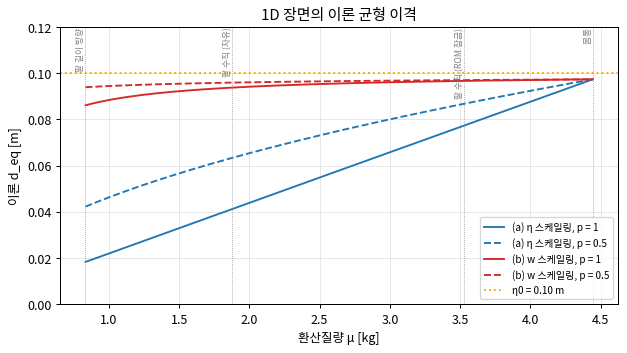

In [7]:
mu_d = np.linspace(MUS[0], MUS[-1], 200)

def label_masses(ax):
    for name, m in REAL.items():
        ax.axvline(m, color='gray', lw=0.6, ls=':')
        ax.text(m, ax.get_ylim()[1], ' ' + name, rotation=90, fontsize=7, va='top', ha='right', color='gray')

fig, ax = plt.subplots(figsize=(8, 4))
for meth, col, lab in [('eta', 'C0', '(a) η 스케일링'), ('w', 'C3', '(b) w 스케일링')]:
    for p, ls in [(1, '-'), (0.5, '--')]:
        ax.plot(mu_d, [d_eq_line(*params(meth, p, m)) for m in mu_d], color=col, ls=ls, label=f'{lab}, p = {p:g}')
ax.axhline(ETA0, color='orange', ls=':', label='η0 = 0.10 m')
ax.set_xlabel('환산질량 μ [kg]'); ax.set_ylabel('이론 d_eq [m]'); ax.set_ylim(0, 0.12)
ax.set_title('1D 장면의 이론 균형 이격'); ax.legend(fontsize=8, loc='lower right'); label_masses(ax)
plt.show()
for meth in ['eta', 'w']:
    for p in [1, 0.5]:
        lo, hi = d_eq_line(*params(meth, p, MUS[0])), d_eq_line(*params(meth, p, MUS[-1]))
        print('%s p=%-3g: 팔 길이 방향 %.4f m → 몸통 %.4f m (%.2f배)' % ('(a) η' if meth == 'eta' else '(b) w', p, lo, hi, hi / lo))

**결과 해석:** (a)는 질량에 따라 이격이 크게 바뀌고(p = 1이면 약 5배, p = 1/2이면 약 2.3배), (b)는 같은 질량 범위에서 1.04~1.13배만 바뀐다. 이 장면의 g(약 2.6)는 가장 작은 w(p = 1에서 18.75)보다 훨씬 작아서, (b)의 곡선은 질량 범위 전체에서 η0 바로 아래에 붙어 있다.

## 4. 1D 확인 장면 — MPPI는 식대로 멈추는가

로봇은 x축 위로만 움직인다(`run_mpc_line`: y 방향 탐색 폭을 0으로 둔 같은 MPPI-MPC). 목표는 (1.50, 0). 5 s 동안 달린 뒤 **마지막 1 s의 평균 간격**을 멈춘 이격으로 잰다. 질량 7개 × 방식 2개 × p 2개, seed 4개.

**예측해 보기:** 2절의 식은 샘플 잡음이 없는 최적해 기준이다. 탐색 폭 σ = 2 m/s²로 후보를 흔드는 MPPI는 식보다 더 가까이 멈출까, 더 멀리 멈출까?

In [8]:
SEEDS = range(4)
CONFIGS = [(m, p) for m in ('eta', 'w') for p in (1, 0.5)]

def sweep(run_one):
    # 모든 (방식, p, μ)에 대해 seed 4개씩 실행. 몸통(μ_ref)처럼 (η, w)가 같은 조합은 한 번만 돌린다
    cache, out = {}, {}
    for meth, p in CONFIGS:
        for mu in MUS:
            eta, w = params(meth, p, mu)
            key = (round(float(eta), 9), round(float(w), 9))
            if key not in cache:
                cache[key] = [run_one(partial(human_cost_uniform, eta=eta, w=w), s) for s in SEEDS]
            out[(meth, p, mu)] = cache[key]
    return out

def line_metrics(r):
    c = clearance_series(r['traj'], r['person'])
    return dict(stop=c[-20:].mean(), wobble=c[-20:].std(), x_end=r['traj'][-1, 0], min=c.min())

def rng_str(vals, fmt='%.3f'):
    return (fmt + '~' + fmt) % (min(vals), max(vals))

t0 = time.time()
res1 = sweep(lambda hc, s: line_metrics(run_mpc_line(hc, goal=GOAL_1D, seed=s)))
print('실행 시간 %.0f s\n' % (time.time() - t0))
print('%-6s %-4s %-6s | %-7s %-6s | %-8s | %-22s | %-6s' % ('방식', 'p', 'μ', 'η', 'w', '식 d_eq', '실측 멈춘 이격 (seed 범위)', '실측−식'))
for meth, p in CONFIGS:
    for mu in MUS:
        eta, w = params(meth, p, mu)
        rs = res1[(meth, p, mu)]
        th = d_eq_line(eta, w)
        st = [r['stop'] for r in rs]
        passed = sum(r['x_end'] > X_FRONT for r in rs)
        print('%-6s %-4g %-6.3f | %-7.4f %-6.1f | %-8.4f | %-22s | %+.3f%s' % (meth, p, mu, eta, w, th, rng_str(st), np.mean(st) - th,
              '  뚫고 지나감 %d개' % passed if passed else ''))
    print()
print('멈춘 뒤 마지막 1 s 동안 간격의 흔들림(표준편차): 최대 %.4f m' % max(r['wobble'] for rs in res1.values() for r in rs))

실행 시간 155 s

방식     p    μ      | η       w      | 식 d_eq   | 실측 멈춘 이격 (seed 범위)     | 실측−식  
eta    1    0.833  | 0.0188  100.0  | 0.0183   | 0.034~0.044            | +0.021
eta    1    1.354  | 0.0305  100.0  | 0.0297   | 0.047~0.061            | +0.024
eta    1    1.875  | 0.0422  100.0  | 0.0412   | 0.054~0.061            | +0.018
eta    1    2.702  | 0.0608  100.0  | 0.0593   | 0.073~0.081            | +0.017
eta    1    3.529  | 0.0794  100.0  | 0.0774   | 0.081~0.098            | +0.014
eta    1    3.987  | 0.0897  100.0  | 0.0874   | 0.097~0.106            | +0.014
eta    1    4.444  | 0.1000  100.0  | 0.0974   | 0.104~0.114            | +0.013

eta    0.5  0.833  | 0.0433  100.0  | 0.0422   | 0.055~0.061            | +0.016
eta    0.5  1.354  | 0.0552  100.0  | 0.0538   | 0.065~0.085            | +0.019
eta    0.5  1.875  | 0.0650  100.0  | 0.0633   | 0.078~0.080            | +0.015
eta    0.5  2.702  | 0.0780  100.0  | 0.0760   | 0.088~0.095            | +0.016
eta    0.5  3.

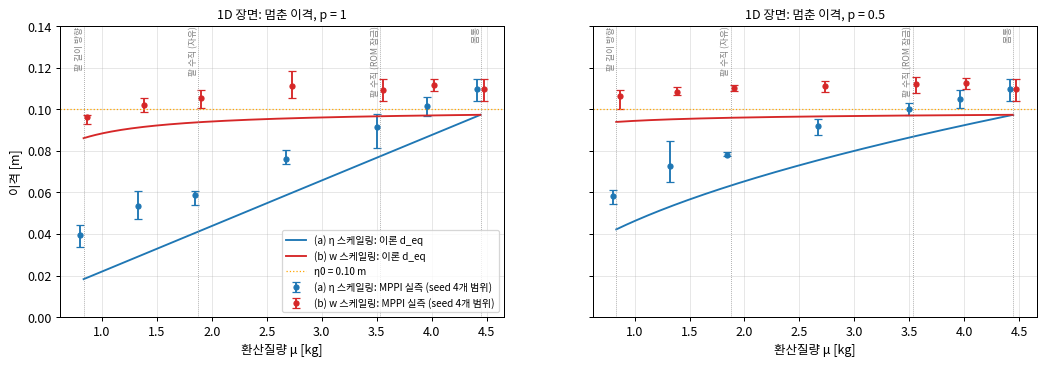

In [9]:
def plot_sweep(res, key, theory, title, ylabel, ylim):
    fig, axs = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
    for ax, p in zip(axs, (1, 0.5)):
        for meth, col, lab, dx in [('eta', 'C0', '(a) η 스케일링', -0.03), ('w', 'C3', '(b) w 스케일링', 0.03)]:
            ax.plot(mu_d, [theory(*params(meth, p, m)) for m in mu_d], color=col, lw=1.5, label=lab + ': 이론 d_eq')
            vals = np.array([[r[key] for r in res[(meth, p, m)]] for m in MUS])
            mid = vals.mean(1)
            ax.errorbar(np.array(MUS) + dx, mid, yerr=[mid - vals.min(1), vals.max(1) - mid], fmt='o', ms=4,
                        color=col, capsize=3, label=lab + ': MPPI 실측 (seed 4개 범위)')
        ax.axhline(ETA0, color='orange', ls=':', lw=1, label='η0 = 0.10 m')
        ax.set_ylim(*ylim); ax.set_xlabel('환산질량 μ [kg]'); ax.set_title(f'{title}, p = {p:g}', fontsize=10)
        label_masses(ax)
    axs[0].set_ylabel(ylabel); axs[0].legend(fontsize=8, loc='lower right')
    plt.show()

plot_sweep(res1, 'stop', d_eq_line, '1D 장면: 멈춘 이격', '이격 [m]', (0, 0.14))

**결과 해석** (표와 그림의 숫자를 보며)
- **모양은 식대로 나왔다.** (a)는 질량에 따라 이격이 커지고, (b)는 질량 범위 전체에서 η0 근처(0.093~0.116 m)에 머문다.
- **(a)는 원점을 지나는 비례가 아니다.** 모든 질량에서 실측이 식보다 1.3~2.4 cm 멀다. 그래서 가벼운 쪽에서는 비율로 보면 차이가 크다. p = 1에서 팔 길이 방향은 식 0.018 m, 실측 0.034~0.044 m다. 팔 길이 방향 → 몸통의 이격 비는 식으로 5.3배인데 실측(seed 평균)으로는 약 2.8배다.
- **(b)는 실측이 η0를 넘는다.** 식으로는 η0(0.10 m)를 넘을 수 없는데, 실측은 가장 가벼운 쪽(w = 18.8, 0.093~0.097 m)을 빼면 대부분 0.10 m 이상이다. 실측도 식보다 1.0~1.5 cm 멀다.
- 이 질량 범위와 이 목표에서는 **경계 안으로 들어간 경우가 없었다**. 가장 작은 w(18.75)도 g(약 2.6)보다 훨씬 크다.

실측이 식보다 먼 이유를 다음 절에서 확인한다.

### 4.1 식과 실측이 어긋나는 이유 — 샘플 잡음

두 가지를 확인한다.
1. **잡음 없는 최적화의 균형점:** 같은 MPC 문제(30칸 입력, 가속도 한계 ±4)를 잡음 없이 정확히 풀었을 때 첫 입력이 0이 되는 자리. 2절의 식은 "30칸 내내 멈춰 있는 계획"만 봤으므로, 계획이 움직일 수 있을 때의 차이(마지막 칸 비용 등)가 여기서 드러난다.
2. **탐색 폭 σ:** σ를 줄이면 후보가 평균 계획 근처에만 퍼진다. 잡음이 원인이라면 σ를 줄일수록 실측이 식에 다가가야 한다.

In [10]:
from scipy.optimize import minimize, brentq

def first_input(x0, eta, w):
    # x0에 멈춰 있는 로봇에서 30칸 x 가속도를 잡음 없이 최적화(L-BFGS-B, ±4 한계)했을 때 첫 입력
    def J(a):
        U = np.stack([a, np.zeros(S.T)], -1)
        P, V = rollout(np.array([x0, 0.0]), np.zeros(2), U)
        return (goal_cost(P, V, U, GOAL_1D) + human_cost_uniform(P[1:], np.zeros((S.T, 2)), eta, w)).sum()
    return minimize(J, np.zeros(S.T), method='L-BFGS-B', bounds=[(-S.U_MAX, S.U_MAX)] * S.T).x[0]

t0 = time.time()
for eta, w in [(ETA0, W0), (ETA0, w_of(REAL['팔 길이 방향'], 1))]:
    th = d_eq_line(eta, w)
    x_eq = brentq(lambda x: first_input(x, eta, w), X_FRONT - th - 0.02, X_FRONT - th + 0.02, xtol=1e-5)
    mp = [r['stop'] for r in res1[('w', 1, MU_REF if w == W0 else REAL['팔 길이 방향'])]]
    print('η %.2f, w %6.2f | 식 %.4f m | 잡음 없는 최적화 %.4f m | MPPI σ=2 %s m' % (eta, w, th, X_FRONT - x_eq, rng_str(mp, '%.4f')))
print('(%.0f s)' % (time.time() - t0))

η 0.10, w 100.00 | 식 0.0974 m | 잡음 없는 최적화 0.0984 m | MPPI σ=2 0.1042~0.1144 m
η 0.10, w  18.75 | 식 0.0861 m | 잡음 없는 최적화 0.0916 m | MPPI σ=2 0.0932~0.0973 m
(39 s)


In [11]:
t0 = time.time()
print('%-7s %-5s | %-24s | %-8s | %s' % ('w', 'σ', '멈춘 이격 (seed 범위)', '식', 'ESS 평균 (마지막 1 s, 17에서 다룸)'))
for w in (W0, w_of(REAL['팔 길이 방향'], 1)):
    for sigma in (2.0, 1.0, 0.5, 0.25):
        rs = [run_mpc_line(partial(human_cost_uniform, eta=ETA0, w=w), goal=GOAL_1D, seed=s, sigma=sigma) for s in SEEDS]
        st = [clearance_series(r['traj'], r['person'])[-20:].mean() for r in rs]
        print('%-7.2f %-5.2f | %-24s | %.4f   | %.0f / %d' % (w, sigma, rng_str(st, '%.4f'), d_eq_line(ETA0, w),
              np.mean([r['ess'][-20:].mean() for r in rs]), S.K))
print('(%.0f s)' % (time.time() - t0))

w       σ     | 멈춘 이격 (seed 범위)          | 식        | ESS 평균 (마지막 1 s, 17에서 다룸)
100.00  2.00  | 0.1042~0.1144            | 0.0974   | 13 / 400
100.00  1.00  | 0.1033~0.1111            | 0.0974   | 35 / 400
100.00  0.50  | 0.1001~0.1040            | 0.0974   | 82 / 400
100.00  0.25  | 0.0971~0.1014            | 0.0974   | 159 / 400
18.75   2.00  | 0.0932~0.0973            | 0.0861   | 25 / 400
18.75   1.00  | 0.0903~0.0953            | 0.0861   | 63 / 400
18.75   0.50  | 0.0858~0.0876            | 0.0861   | 133 / 400
18.75   0.25  | 0.0956~0.1021            | 0.0861   | 233 / 400
(45 s)


**결과 해석**
- **잡음 없이 풀면 식과 가깝다.** w = 100에서 1 mm, w = 18.75에서 5.5 mm 차이다. 2절의 식은 "30칸 내내 멈춰 있는 계획"만 비교했고, 실제 최적 계획은 칸마다 조금씩 움직일 수 있어서 생기는 차이다. 실측과 식의 차이(1~2 cm)보다 작다.
- **σ를 줄이면 실측이 식에 다가간다.** w = 100에서는 σ = 2 → 1 → 0.5 → 0.25로 줄일수록 멈춘 이격이 0.104~0.114에서 0.097~0.101 m로 줄어 식(0.097)과 잡음 없는 최적화(0.098)에 닿는다. w = 18.75에서는 σ = 0.5에서 0.086~0.088 m로 식(0.086)에 닿는다. 그러므로 실측이 식보다 먼 주된 이유는 **샘플 잡음**이다. σ가 크면 후보 계획들이 평균 주변으로 넓게 흔들리고, 그중 사람 쪽으로 흔들린 후보는 η 안에 들어가 비싸진다. 가중평균은 그런 후보를 피하므로 평균 계획이 더 물러난다.
- 가속도 한계(±4)는 멈춰 있는 상태에서는 걸리지 않으므로 이 차이와 관계없다.
- 예외가 하나 있다. w = 18.75, σ = 0.25에서는 다시 0.096~0.102 m로 식에서 멀어졌다. 이때 ESS가 400개 중 233개로, 가중치가 많은 후보에 고르게 퍼져 있다. 이 노트에서는 원인을 따로 확인하지 않았다. MPPI 내부 상태와 이격의 관계는 17에서 다룬다.

**정리:** 1D에서 식은 "잡음 없는 MPC"의 균형점을 수 mm 안에서 맞힌다. MPPI는 탐색 폭 σ = 2의 잡음 때문에 그보다 1~2 cm 더 멀리 멈춘다. 그래서 (a)의 실측은 원점을 지나는 직선이 아니라 위로 떠 있는 선에 가깝다.

## 5. 2D 우회 장면 — 지나가며 얼마나 가까이 가는가

14의 기본 장면(사람 정지, 기준 자세, 목표 (2.0, 0))으로 돌아간다. 로봇은 사람을 돌아서 지나간다. **실행 전체의 최소 이격**을 잰다.

2D에서는 균형 상태로 멈추는 것이 아니라 움직이면서 지나간다. 또 사람 옆을 지날 때 목표 쪽 당김은 대부분 진행 방향(+x)이고, 사람 쪽으로 당기는 성분은 작다. 그래서 식의 g 자리에 "가장 가까웠던 순간, 목표 당김 중 사람 쪽 성분"을 넣어 비교해 본다.

**예측해 보기:** 사람 쪽 당김 성분이 작으면 $d_{eq} = \eta(1 - g/w)$는 무엇에 가까워질까? 그러면 (b)의 곡선은 어떤 모양일까?

In [12]:
def toward_person(p, h=1e-6):
    # 점 p에서 가장 가까운 분절 쪽으로 간격이 가장 빨리 줄어드는 단위 방향 (−∇간격)
    gap = lambda q: segment_gaps(q).min()
    grad = np.array([(gap(p + h * e) - gap(p - h * e)) / (2 * h) for e in (ex, ey)])
    return -grad / np.linalg.norm(grad)

def pass_metrics(r):
    c = clearance_series(r['traj'], r['person'])
    i = int(np.argmin(c))
    p = r['traj'][i]
    g_perp = C_PULL * (S.GOAL - p) @ toward_person(p)          # 목표 당김 중 사람 쪽 성분 (칸 하나 기준)
    side = r['traj'][np.argmax(np.abs(r['traj'][:, 1])), 1]
    return dict(min=c[i], g=g_perp, seg=SEG_NAMES[int(np.argmin(segment_gaps(p)))], side='위' if side > 0 else '아래',
                arrive=arrival_time(r['traj']), cmd=command_change(r['us']))

t0 = time.time()
res2 = sweep(lambda hc, s: pass_metrics(run_mpc(static_person, human_cost=hc, seed=s)))
print('실행 시간 %.0f s\n' % (time.time() - t0))
G2D = float(np.mean([r['g'] for rs in res2.values() for r in rs]))
print('가장 가까웠던 순간의 사람 쪽 당김 g: 평균 %.2f (범위 %s), 가까웠던 분절: %s'
      % (G2D, rng_str([r['g'] for rs in res2.values() for r in rs], '%.2f'),
         sorted({r['seg'] for rs in res2.values() for r in rs})))
print()
print('%-6s %-4s %-6s | %-7s %-6s | %-8s | %-20s | %-12s | %s' % ('방식', 'p', 'μ', 'η', 'w', '식 d_eq', '실측 최소 이격 (범위)', '돌아간 쪽', '명령 변화량 [m/s²]'))
for meth, p in CONFIGS:
    for mu in MUS:
        eta, w = params(meth, p, mu)
        rs = res2[(meth, p, mu)]
        print('%-6s %-4g %-6.3f | %-7.4f %-6.1f | %-8.4f | %-20s | %-12s | %s' % (meth, p, mu, eta, w, d_eq(eta, G2D, w),
              rng_str([r['min'] for r in rs]), ''.join(r['side'] for r in rs), rng_str([r['cmd'] for r in rs], '%.2f')))
    print()

실행 시간 126 s

가장 가까웠던 순간의 사람 쪽 당김 g: 평균 0.77 (범위 0.52~0.91), 가까웠던 분절: ['torso']

방식     p    μ      | η       w      | 식 d_eq   | 실측 최소 이격 (범위)        | 돌아간 쪽        | 명령 변화량 [m/s²]
eta    1    0.833  | 0.0188  100.0  | 0.0186   | 0.031~0.039          | 위위위위         | 1.27~1.40
eta    1    1.354  | 0.0305  100.0  | 0.0302   | 0.040~0.048          | 위위위위         | 1.24~1.41
eta    1    1.875  | 0.0422  100.0  | 0.0419   | 0.049~0.055          | 위위위위         | 1.25~1.41
eta    1    2.702  | 0.0608  100.0  | 0.0603   | 0.064~0.070          | 위위위위         | 1.27~1.52
eta    1    3.529  | 0.0794  100.0  | 0.0788   | 0.078~0.086          | 위위아래위        | 1.25~1.43
eta    1    3.987  | 0.0897  100.0  | 0.0890   | 0.087~0.091          | 아래아래아래위      | 1.29~1.44
eta    1    4.444  | 0.1000  100.0  | 0.0992   | 0.096~0.103          | 위아래아래위       | 1.29~1.48

eta    0.5  0.833  | 0.0433  100.0  | 0.0430   | 0.050~0.056          | 위위위위         | 1.25~1.41
eta    0.5  1.354  | 0.0552  100.0  | 0.05

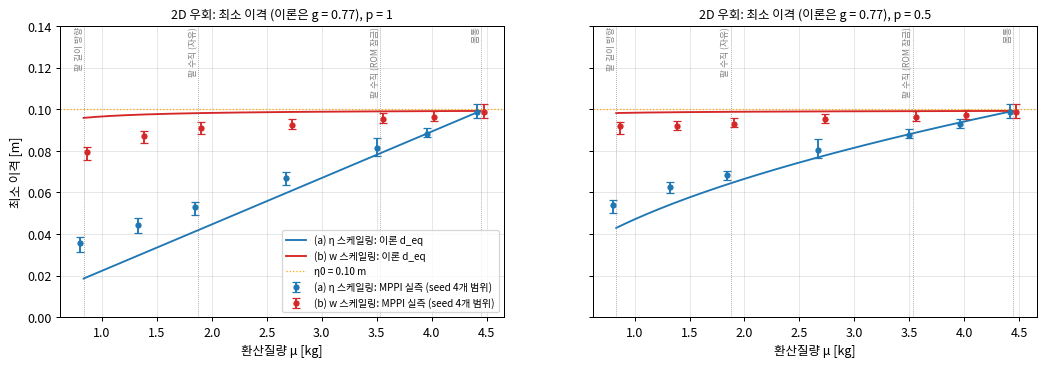

In [13]:
plot_sweep(res2, 'min', lambda eta, w: d_eq(eta, G2D, w), f'2D 우회: 최소 이격 (이론은 g = {G2D:.2f})', '최소 이격 [m]', (0, 0.14))

**결과 해석** (표와 그림의 숫자를 보며)
- 가장 가까웠던 순간은 모든 실행에서 몸통 옆을 지날 때였고, 그때 사람 쪽 당김 g는 0.52~0.91(평균 0.77)로 1D(약 2.6)보다 작다. 그래서 이론 곡선은 사실상 (a) η(μ), (b) η0 그 자체다.
- **2D에서도 모양은 같다.** (a)는 질량에 따라 최소 이격이 커지고(p = 1에서 0.031~0.039 → 0.096~0.103 m), (b)는 좁은 범위(p = 1에서 0.076~0.103 m)에 머문다. 어느 경우에도 사람과 겹치지 않았다.
- **식과 딱 맞지는 않는다.** 차이가 1D와 다르게 나타난다.
  - (a)는 가벼운 쪽에서 실측이 식보다 멀고(p = 1, 팔 길이 방향: 식 0.019 m, 실측 0.031~0.039 m. 1D와 같은 방향), 몸통 쪽에서는 식과 거의 같다(1D에서는 몸통 쪽도 1.3 cm 멀었다).
  - (b)는 가벼운 쪽에서 실측이 식보다 **가깝다**. p = 1, 팔 길이 방향(w = 18.8)에서 식 0.096 m, 실측 0.076~0.082 m로 η 경계 안쪽 약 2 cm까지 들어왔다. 1D에서 (b)는 거의 평평했는데, 2D에서는 w가 작을수록 최소 이격이 줄어드는 경향이 뚜렷하다.
  - 움직이며 지나갈 때는 정지 균형식이 다루지 않는 것들(지나가는 속도, 돌아 들어가는 궤적의 곡률, 잡음으로 잠깐 들어갔다 나오는 것)이 최소 이격을 정한다. 이 노트에서는 각각의 크기를 나누어 재지 않았다.
- 명령 변화량(떨림 지표)은 모든 설정에서 1.24~1.53 m/s²로, w나 η에 따른 뚜렷한 변화가 없었다.
- 돌아간 쪽(위/아래)은 seed와 설정에 따라 다르다. 질량이 방향과 무관해서 장면이 위아래 대칭이기 때문이다(방향별 질량은 16).

## 6. 국소 균형만 보면 놓치는 것 — 돌아갈 수 없고 목표가 멀 때

2절의 식은 "멈춘 자리 근처에서 당김과 밀어냄이 같은가"만 본다. 그런데 MPPI는 후보를 넓게 뿌리므로, 멀리 떨어진 전혀 다른 계획(예: 사람을 뚫고 지나가기)이 더 싸면 그쪽을 고른다.

5절의 2D 장면은 목표가 (2.0, 0)으로 사람 뒤 0.5 m에 있다. 돌아갈 수 있으니 문제가 없었다. **돌아갈 수 없는** 1D에서 목표를 이 (2.0, 0)에 두면 어떻게 될까? 이 절만 목표 위치가 4절과 다르다.

**예측해 보기:** 목표가 멀면 g가 커진다(D ≈ 1.3 m → g ≈ 4.3). 그래도 가장 작은 w(18.75)보다 작으니 식으로는 모두 멈춰야 한다. 실제로도 그럴까?

In [14]:
t0 = time.time()
print('목표 (2.0, 0), 1D (x축 위로만)')
print('%-6s %-4s %-6s | %-7s %-6s | %-8s | %s' % ('방식', 'p', 'μ', 'η', 'w', '식 d_eq', 'seed 4개 결과: 멈춘 이격 [m] 또는 통과(처음 겹친 시각, 그때 속도)'))
L_FAR = S.GOAL[0] - X_FRONT
for meth, p in [('w', 1), ('w', 0.5), ('eta', 1)]:
    for mu in MUS:
        eta, w = params(meth, p, mu)
        rs = [run_mpc_line(partial(human_cost_uniform, eta=eta, w=w), goal=S.GOAL, seed=s) for s in SEEDS]
        outs = []
        for r in rs:
            c = clearance_series(r['traj'], r['person'])
            if r['traj'][-1, 0] > S.TORSO_C[0]:
                i = int(np.argmax(c < 0))
                outs.append('통과(%.2f s, %.1f m/s)' % (i * S.DT, (r['traj'][i, 0] - r['traj'][i - 1, 0]) / S.DT))
            else:
                outs.append('%.3f' % c[-20:].mean())
        print('%-6s %-4g %-6.3f | %-7.4f %-6.1f | %-8.4f | %s' % (meth, p, mu, eta, w, d_eq_line(eta, w, L_FAR), '  '.join(outs)))
    print()
print('(%.0f s)' % (time.time() - t0))

목표 (2.0, 0), 1D (x축 위로만)
방식     p    μ      | η       w      | 식 d_eq   | seed 4개 결과: 멈춘 이격 [m] 또는 통과(처음 겹친 시각, 그때 속도)
w      1    0.833  | 0.1000  18.8   | 0.0774   | 통과(0.70 s, 2.4 m/s)  통과(0.70 s, 2.3 m/s)  통과(0.70 s, 2.3 m/s)  통과(0.70 s, 2.3 m/s)
w      1    1.354  | 0.1000  30.5   | 0.0860   | 통과(0.70 s, 2.4 m/s)  통과(0.70 s, 2.4 m/s)  통과(0.75 s, 2.3 m/s)  통과(0.70 s, 2.3 m/s)
w      1    1.875  | 0.1000  42.2   | 0.0898   | 0.095  0.098  0.100  통과(0.70 s, 2.3 m/s)
w      1    2.702  | 0.1000  60.8   | 0.0929   | 0.100  0.102  0.102  0.100
w      1    3.529  | 0.1000  79.4   | 0.0946   | 0.102  0.108  0.105  0.103
w      1    3.987  | 0.1000  89.7   | 0.0952   | 0.102  0.099  0.119  0.110
w      1    4.444  | 0.1000  100.0  | 0.0957   | 0.104  0.101  0.111  0.105

w      0.5  0.833  | 0.1000  43.3   | 0.0901   | 0.100  0.097  0.101  통과(0.70 s, 2.3 m/s)
w      0.5  1.354  | 0.1000  55.2   | 0.0922   | 0.105  0.100  0.108  0.099
w      0.5  1.875  | 0.1000  65.0   | 0.0934   | 0.109  

w가 작은 몇 개(표)에서 로봇은 멈추지 않고 사람을 **뚫고 지나가** 목표에 도착했다. 식으로는 g ≈ 4.3 < w라 멈춰야 하는데도 그렇다. 통과한 실행은 모두 출발 직후부터 사람을 향해 가속해 2 m/s 넘는 속도로 처음 겹쳤다. 사람 앞에서 멈췄다가 밀려 들어간 것이 아니라, **처음부터 뚫고 지나가는 계획**을 골랐다.

이유를 비용으로 확인한다. 시작점(정지)에서 30칸 x 가속도를 잡음 없이 최적화한다. 초기값을 여러 개(최대 가속 k칸 → 최대 감속 k칸) 써서, 끝 위치가 사람 앞인 계획(**멈추기**)과 사람 뒤인 계획(**통과하기**) 중 각각 가장 싼 것을 찾아 비교한다.

In [15]:
def start_plan_cost(a, goal, w):
    U = np.stack([a, np.zeros(S.T)], -1)
    P, V = rollout(S.START, np.zeros(2), U)
    return (goal_cost(P, V, U, goal) + human_cost_uniform(P[1:], np.zeros((S.T, 2)), ETA0, w)).sum()

def bang(k):
    a = np.zeros(S.T); a[:k] = S.U_MAX; a[k:2 * k] = -S.U_MAX
    return a

def best_by_kind(goal, w, inits=(6, 8, 10, 12, 14)):
    best = {}
    for k in inits:
        r = minimize(start_plan_cost, bang(k), args=(goal, w), method='L-BFGS-B', bounds=[(-S.U_MAX, S.U_MAX)] * S.T)
        U = np.stack([r.x, np.zeros(S.T)], -1)
        x_end = rollout(S.START, np.zeros(2), U)[0][-1, 0]
        kind = '멈추기' if x_end < X_FRONT else ('통과하기' if x_end > S.TORSO_C[0] + S.TORSO_R else None)
        if kind and r.fun < best.get(kind, np.inf):
            best[kind] = r.fun
    return best

t0 = time.time()
for name, goal in [('목표 (2.0, 0) — 6절', S.GOAL), ('목표 (1.50, 0) — 4절', GOAL_1D)]:
    print(name)
    for w in (10, 20, 30, 40, 60, 80, 100):
        b = best_by_kind(goal, w)
        st, th = b.get('멈추기', np.nan), b.get('통과하기', np.nan)
        cheaper = '통과하기' if th < st or np.isnan(st) else '멈추기'
        print('  w = %3d | 멈추기 %s | 통과하기 %s | 더 싼 쪽: %s' % (w, '%.1f' % st if np.isfinite(st) else '국소해 없음',
              '%.1f' % th if np.isfinite(th) else '국소해 없음', cheaper))
print('(%.0f s)' % (time.time() - t0))

목표 (2.0, 0) — 6절
  w =  10 | 멈추기 국소해 없음 | 통과하기 50.6 | 더 싼 쪽: 통과하기
  w =  20 | 멈추기 국소해 없음 | 통과하기 59.1 | 더 싼 쪽: 통과하기
  w =  30 | 멈추기 국소해 없음 | 통과하기 67.4 | 더 싼 쪽: 통과하기
  w =  40 | 멈추기 국소해 없음 | 통과하기 75.6 | 더 싼 쪽: 통과하기
  w =  60 | 멈추기 99.8 | 통과하기 91.8 | 더 싼 쪽: 통과하기
  w =  80 | 멈추기 100.2 | 통과하기 107.7 | 더 싼 쪽: 멈추기
  w = 100 | 멈추기 100.6 | 통과하기 123.2 | 더 싼 쪽: 멈추기
목표 (1.50, 0) — 4절
  w =  10 | 멈추기 국소해 없음 | 통과하기 32.9 | 더 싼 쪽: 통과하기
  w =  20 | 멈추기 42.1 | 통과하기 43.5 | 더 싼 쪽: 멈추기
  w =  30 | 멈추기 42.5 | 통과하기 53.9 | 더 싼 쪽: 멈추기
  w =  40 | 멈추기 42.8 | 통과하기 63.7 | 더 싼 쪽: 멈추기
  w =  60 | 멈추기 43.0 | 통과하기 82.2 | 더 싼 쪽: 멈추기
  w =  80 | 멈추기 43.2 | 통과하기 99.7 | 더 싼 쪽: 멈추기
  w = 100 | 멈추기 43.3 | 통과하기 116.7 | 더 싼 쪽: 멈추기
(65 s)


**결과 해석** (위 출력을 보며)
- 목표가 멀면 멈추는 계획은 30칸 내내 큰 목표 비용(D ≈ 1.3 m의 제곱)을 낸다. 통과하는 계획은 사람 안에 있는 몇 칸만 사람 비용을 낸다. 사람 비용은 겹친 뒤에도 기울기가 w로 일정해서 **높이가 w에 비례하는 유한한 언덕**이다. w가 작으면 언덕을 넘는 비용이 목표 비용 절약분보다 싸다.
- 잡음 없는 최적화로 보면 두 계획의 비용이 뒤바뀌는 w가 목표 (2.0, 0)에서는 60~80 사이, 목표 (1.50, 0)에서는 10~20 사이다. 목표가 멀수록 통과하기가 이기는 w 범위가 넓다. "국소해 없음"은 사람 앞에서 끝나는 초기값에서 시작해도 최적화가 통과하는 계획으로 넘어갔다는 뜻이다.
- **목표 (1.50, 0):** MPPI 결과(w = 18.75 멈춤, 2절의 w = 2 통과)는 잡음 없는 최적화의 경계(10~20)와 어긋나지 않는다. 4절의 가장 가벼운 설정(w = 18.75)이 이 경계 바로 위에 있었다.
- **목표 (2.0, 0):** 경계 값이 MPPI 실측과 다르다. 잡음 없는 최적화는 w = 60까지 통과하기가 더 싸다고 하는데, MPPI는 w = 30.5 이하에서 모두 통과, w ≈ 42~43에서 seed 4개 중 1개 통과, w ≥ 55에서 모두 멈췄다. MPPI가 더 작은 w에서야 통과하기를 골랐다. 통과하려면 30칸에 걸친 큰 가속·감속을 맞춰야 하는데, 평균 주변으로 흔들린 후보들 가운데 그런 계획이 얼마나 자주 나오는지가 영향을 줄 수 있다. 이 노트에서는 그 원인을 확인하지 않았다.
- (a) η 스케일링은 w = 100을 유지한다. 표에서 (a)는 모두 멈췄다. 왜 그런지 아래 그림으로 확인한다.

### 사람을 가로지르는 비용 언덕

사람 중심을 지나는 x축(y = 0) 위에서, 로봇 중심이 x에 있을 때 칸 하나의 사람 비용을 그린다. 팔 끝 앞부터 몸통 뒤까지, 사람과 겹친 구간(d < 0)도 포함한다. 질량은 6절에서 통과가 일어난 μ = 0.833, 1.354 kg(w ≤ 30.5), 일부 통과한 1.875 kg(w = 42.2), 그리고 기준인 몸통(4.444 kg)이다(p = 1).

μ      | (a) η 스케일링: 높이 / 넓이        | (b) w 스케일링: 높이 / 넓이       
0.833  |   20.9 / 7.94   (몸통의  70%) |    4.7 / 2.12   (몸통의  19%)
1.354  |   21.5 / 8.39   (몸통의  74%) |    7.6 / 3.44   (몸통의  30%)
1.875  |   22.1 / 8.86   (몸통의  78%) |   10.5 / 4.76   (몸통의  42%)
4.444  |   25.0 / 11.29  (몸통의 100%) |   25.0 / 11.29  (몸통의 100%)
넓이 = 언덕 아래 면적 ∫ 비용 dx [m]. 사람 밖(d ≥ 0) 구간의 넓이: 0.011, 0.030, 0.058, 0.331 (a)


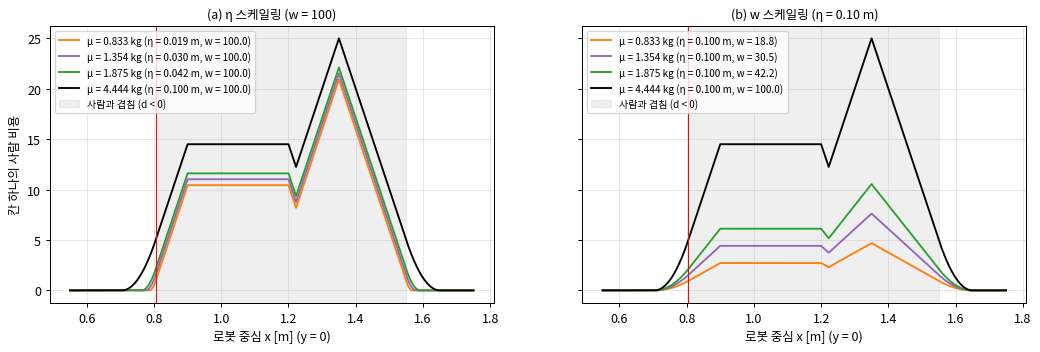

In [16]:
x = np.linspace(0.55, 1.75, 2401)
dx = x[1] - x[0]
gap_x = segment_gaps(np.stack([x, np.zeros_like(x)], -1)).min(-1)     # 가장 가까운 분절과의 간격 (겹치면 음수)
PASS_MUS = [MUS[0], MUS[1], MUS[2], MU_REF]
fig, axs = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
print('%-6s | %-26s | %-26s' % ('μ', '(a) η 스케일링: 높이 / 넓이', '(b) w 스케일링: 높이 / 넓이'))
rows = {mu: [] for mu in PASS_MUS}
for ax, (meth, title) in zip(axs, [('eta', '(a) η 스케일링 (w = 100)'), ('w', '(b) w 스케일링 (η = 0.10 m)')]):
    for mu, col in zip(PASS_MUS, ['C1', 'C4', 'C2', 'k']):
        eta, w = params(meth, 1, mu)
        c = eta_cost(gap_x, eta, w)
        rows[mu].append((c.max(), c.sum() * dx))
        ax.plot(x, c, color=col, label=f'μ = {mu:.3f} kg (η = {eta:.3f} m, w = {w:.1f})')
    ax.axvspan(x[gap_x < 0].min(), x[gap_x < 0].max(), color='gray', alpha=0.12, label='사람과 겹침 (d < 0)')
    ax.axvline(X_FRONT, color='r', lw=0.8)
    ax.set_xlabel('로봇 중심 x [m] (y = 0)'); ax.set_title(title, fontsize=10); ax.legend(fontsize=8, loc='upper left')
axs[0].set_ylabel('칸 하나의 사람 비용')
plt.show()
for mu in PASS_MUS:
    (ha, aa), (hb, ab) = rows[mu]
    print('%-6.3f | %6.1f / %-6.2f (몸통의 %3.0f%%) | %6.1f / %-6.2f (몸통의 %3.0f%%)' % (mu, ha, aa, 100 * aa / rows[MU_REF][0][1], hb, ab, 100 * ab / rows[MU_REF][1][1]))
print('넓이 = 언덕 아래 면적 ∫ 비용 dx [m]. 사람 밖(d ≥ 0) 구간의 넓이:',
      ', '.join('%.3f' % (eta_cost(gap_x[gap_x >= 0], *params('eta', 1, mu)).sum() * dx) for mu in PASS_MUS), '(a)')

**결과 해석:** 그림으로 설명된다. 겹친 뒤의 비용은 $w\,\big((\eta - d) - \eta/2\big) \approx w\,(-d)$라서 사람 안쪽 깊이(몸통 중심에서 d = −0.20 m)가 언덕 높이를 정하고, η는 사람 밖의 좁은 시작 구간만 바꾼다. 그래서 (a)는 η를 몸통의 1/5로 줄여도 언덕 높이(20.9~22.1 vs 25.0)와 넓이(몸통의 70~78%)가 크게 줄지 않고, (b)는 언덕 전체가 w에 비례해 모두 통과한 질량에서 넓이가 몸통의 19~30%(일부 통과한 w = 42.2에서 42%)로 낮아진다. 6절 표에서 (a)는 언덕이 높아 모두 멈췄고, (b)는 언덕이 낮아 목표 비용 절약분이 언덕을 넘는 값보다 커지면서 뚫고 지나갔다.

**연구 결정에 주는 뜻:** w 스케일링은 가벼운 분절의 비용 언덕을 낮춘다. 돌아갈 길이 없고 목표가 멀면, 가벼운 분절(팔)을 **뚫고 지나가는** 계획이 최적이 될 수 있다. η 스케일링에서는 이격이 줄어들 뿐 언덕 높이는 유지된다. 이것은 $d_{eq}$ 식(국소 균형)만으로는 보이지 않는다.

## 7. 정리 — η 스케일링 vs w 스케일링

| | (a) η 스케일링 | (b) w 스케일링 |
|---|---|---|
| 이론 $d_{eq}$ | $\eta(\mu)(1 - g/w_0)$: 질량에 비례 | $\eta_0(1 - g/w(\mu))$: η0 아래에서 포화 |
| 1D 실측 (목표 1.50) | 0.034~0.044 → 0.104~0.114 m. 식보다 1.3~2.4 cm 멀다(샘플 잡음) | 0.093~0.116 m. η0 근처, 대부분 η0보다 멀다 |
| 2D 실측 (우회) | 0.031~0.039 → 0.096~0.103 m (p = 1) | 0.076~0.103 m (p = 1). 가벼운 쪽에서 식보다 약 2 cm 가깝다 |
| 경계 안으로 | 이 노트에서 없음 | 국소 균형(g ≥ w)은 이 질량 범위에서 없음(범위 밖 w = 2에서 확인). 돌아갈 수 없고 목표가 먼 1D에서는 가벼운 쪽이 뚫고 지나감(6절) |
| 질량이 바꾸는 것 | 피하는 **거리** | 경계의 **단단함** |

**연구의 질량 배치 결정에 쓸 수 있는 관찰:** "질량이 클수록 더 멀리"를 원하면 질량은 η에 넣어야 한다. w에 넣으면 거리는 거의 바뀌지 않고, 가벼운 쪽의 비용 언덕이 낮아져 국소 균형식이 놓치는 실패(뚫고 지나가기)가 생길 수 있다. 단, η에 넣어도 실제 이격은 MPPI 잡음 때문에 식보다 멀어서 η(μ)에 정확히 비례하지는 않는다(1D에서 식 5.3배, 실측 약 2.8배). 필요 이격 거리를 η로 정할 때(19) 이 차이를 고려해야 한다. 이 노트는 한 장면, seed 4개, 질량이 방향과 무관한 경우의 결과다.

## 핵심 정리

- 질량은 η(켜지는 거리) 또는 w(세기)에 넣을 수 있다.
- 균형 이격 $d_{eq} = \eta(1 - g/w)$. g는 목표가 로봇을 당기는 기울기(칸 하나 기준, 목표까지 거리에 비례).
- η에 넣으면 이격이 질량에 비례해서 커진다. w에 넣으면 이격은 η 아래에서 포화한다.
- g ≥ w이면 균형점이 없어 경계 안으로 들어간다. 또 국소 균형이 있어도, 비용 언덕(높이 ∝ w)을 넘는 계획이 더 싸면 MPPI는 그쪽을 고른다.
- 1D에서 MPPI 실측은 샘플 잡음 때문에 식보다 1~2 cm 더 멀다(σ를 줄이면 식에 다가간다). 2D에서 지나갈 때는 w가 작을수록 식보다 가까워진다.

## 확인 문제

<details><summary>1. (계산) η = 0.10 m, g = 20, w = 100이면 d_eq는?</summary>

0.10 × (1 − 20/100) = **0.08 m**
</details>

<details><summary>2. (계산) η = 0.05 m, g = 5, w = 50이면 d_eq는? 같은 η, g에서 w = 4라면?</summary>

0.05 × (1 − 0.1) = **0.045 m**. w = 4이면 g ≥ w라 **균형점이 없다**(경계 안으로 들어간다).
</details>

<details><summary>3. (보기) p = 1, g ≪ w일 때 질량이 2배가 되면 이격은? (a) η 스케일링 / (b) w 스케일링 각각 고르시오: ① 거의 2배 ② 거의 그대로 ③ 절반</summary>

(a) **①** 거의 2배 ($d_{eq}$가 η(μ)에 비례). (b) **②** 거의 그대로 ($d_{eq}$는 η0 아래에서 포화).
</details>

<details><summary>4. (계산) p = 1/2이면 질량이 4배일 때 (a)의 η는 몇 배가 되는가?</summary>

$\sqrt{4}$ = **2배**
</details>

<details><summary>5. (보기) 4.1절에서 MPPI의 멈춘 이격이 식보다 컸던 주된 이유는? (a) 가속도 한계 (b) 샘플 잡음(탐색 폭 σ) (c) 목표 비용의 마지막 칸 가중치</summary>

**(b)**. σ를 줄이자 식에 다가갔다. 잡음 없는 최적화는 식과 수 mm 안에서 같았으므로 (c)의 효과는 작다. 멈춰 있을 때는 (a)가 걸리지 않는다.
</details>

<details><summary>6. (보기) 6절에서 1D 로봇이 사람을 뚫고 지나간 조건을 모두 고르시오. (a) 돌아갈 수 없음 (b) 목표가 멂 (c) w가 작음 (d) η가 작음</summary>

**(a), (b), (c)**. η만 작아진 (a) 방식(w = 100)은 모두 멈췄다.
</details>

## 다음 노트

**[16 · 방향별 질량](16_directional_mass.ipynb)**: 이 노트에서는 질량을 사람 전체에 하나만 썼다. 16에서는 분절과 충돌 방향 u에 따라 다른 질량 m_h(u)를 η(u)에 넣는다. 위·아래 대칭이 깨지면서 로봇이 어느 쪽으로 돌아가는지가 질량으로 정해지는지 본다.